# Лабораторная работа 3. Продвинутые модели ML и интерпретация
**Вариант 1:** Titanic, `survived`. Бустинги: XGBoost, LightGBM, CatBoost. Optuna: `learning_rate`, `max_depth`, `n_estimators`.
Стекинг: LightGBM + RandomForest + LogisticRegression. Дисбаланс: взвешивание классов. SHAP: summary, dependence (+ bar и waterfall из общей части задания).

Все сравнения проводятся на 5-фолдовой стратифицированной CV по train. Test (20%) откладываем сразу и используем один раз, в финале.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # чтобы импортировать src/ из notebooks/
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # LightGBM/sklearn предупреждают об именах признаков

import matplotlib.pyplot as plt
import optuna
import pandas as pd
import shap
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

from src.data import RANDOM_STATE, load_xy
from src.utils import CV, build_pipeline, cv_auc, cv_report, evaluate, save_model, tree_pipeline

X, y = load_xy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"train {len(X_train)}, test {len(X_test)}, доля выживших в train: {y_train.mean():.3f}")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train 712, test 179, доля выживших в train: 0.383


## 1. Предобработка
Пайплайн `tree_pipeline` из `src/utils.py`:
1. `add_features` (из лабы 2): `family_size`, `fare_per_person`;
2. категории (`pclass`, `sex`, `embarked`) переводятся в порядковые коды через `OrdinalEncoder`. Дереву one-hot не нужен: оно само делит значения порогом;
3. масштабирование **не делаем**: деревья инвариантны к монотонным преобразованиям признаков;
4. пропуски (`age` ≈ 20%) **не заполняем**: XGBoost/LightGBM/CatBoost умеют работать с NaN сами. На каждом сплите они выбирают, в какую ветку отправить пропуски. Для RandomForest в стекинге включаем медиану/моду (`impute=True`).

Вся предобработка находится внутри пайплайна, поэтому на каждом фолде CV она обучается только на его train-части.

## 2. Базовые модели: три бустинга с параметрами по умолчанию
Метрики: ROC-AUC (основная), PR-AUC и F1. Также фиксируем время обучения на одном фолде.

In [2]:
base_models = {
    "XGBoost": tree_pipeline(XGBClassifier(random_state=RANDOM_STATE)),
    "LightGBM": tree_pipeline(LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)),
    "CatBoost": tree_pipeline(CatBoostClassifier(random_state=RANDOM_STATE, verbose=0)),
}
baseline = cv_report(base_models, X_train, y_train)
baseline.round(4)

,roc_auc,pr_auc,f1,roc_auc_std,fit_time_s
XGBoost,0.8661,0.8430,0.7495,0.0205,0.0417
LightGBM,0.8688,0.8435,0.7519,0.0267,0.0454
CatBoost,0.8789,0.8504,0.7554,0.0235,0.5817


**Выбор библиотеки — LightGBM.** CatBoost по умолчанию выигрывает примерно 0.01 ROC-AUC. Это меньше разброса между фолдами (std ≈ 0.02–0.03), то есть разница статистически не значима. При этом CatBoost обучается в 15–20 раз дольше: у него по умолчанию 1000 деревьев против 100.
LightGBM самый быстрый, поэтому за то же время Optuna успевает перебрать больше конфигураций. Кроме того, LightGBM стоит в стекинге по варианту.
У LightGBM дефолтные параметры (`num_leaves=31`, 100 деревьев, `learning_rate=0.1`) рассчитаны на большие датасеты, а на 712 строках они переобучаются. Поэтому от подбора гиперпараметров у него ожидается наибольший прирост.

## 3. Оптимизация гиперпараметров (Optuna)
- Сэмплер **TPE** (Tree-structured Parzen Estimator) строит вероятностную модель «хороших» и «плохих» областей и предлагает точки, где отношение плотностей наибольшее. Это умнее перебора по сетке. `seed` зафиксирован, поэтому результат воспроизводится.
- Внутри `objective` считается среднее ROC-AUC на тех же 5 фолдах, что и везде. Test в подборе не участвует.
- Пространство поиска по варианту: `learning_rate` в лог-шкале (0.005–0.3), `max_depth` 2–8, `n_estimators` 50–1000.

In [3]:
optuna.logging.set_verbosity(optuna.logging.WARNING)


def lgbm(**params):
    return LGBMClassifier(**params, random_state=RANDOM_STATE, verbose=-1)


def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "n_estimators": trial.suggest_int("n_estimators", 50, 1000, step=50),
    }
    return cv_auc(tree_pipeline(lgbm(**params)), X_train, y_train)[0]


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=50)
best_params = study.best_params
print(f"best CV ROC-AUC: {study.best_value:.4f}")
best_params

best CV ROC-AUC: 0.8897


{'learning_rate': 0.00868223824784432, 'max_depth': 2, 'n_estimators': 550}

/tmp/ipykernel_1251/4052195749.py:4: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot(study).figure.savefig(f"../reports/lab3_optuna_{name}.png", bbox_inches="tight")


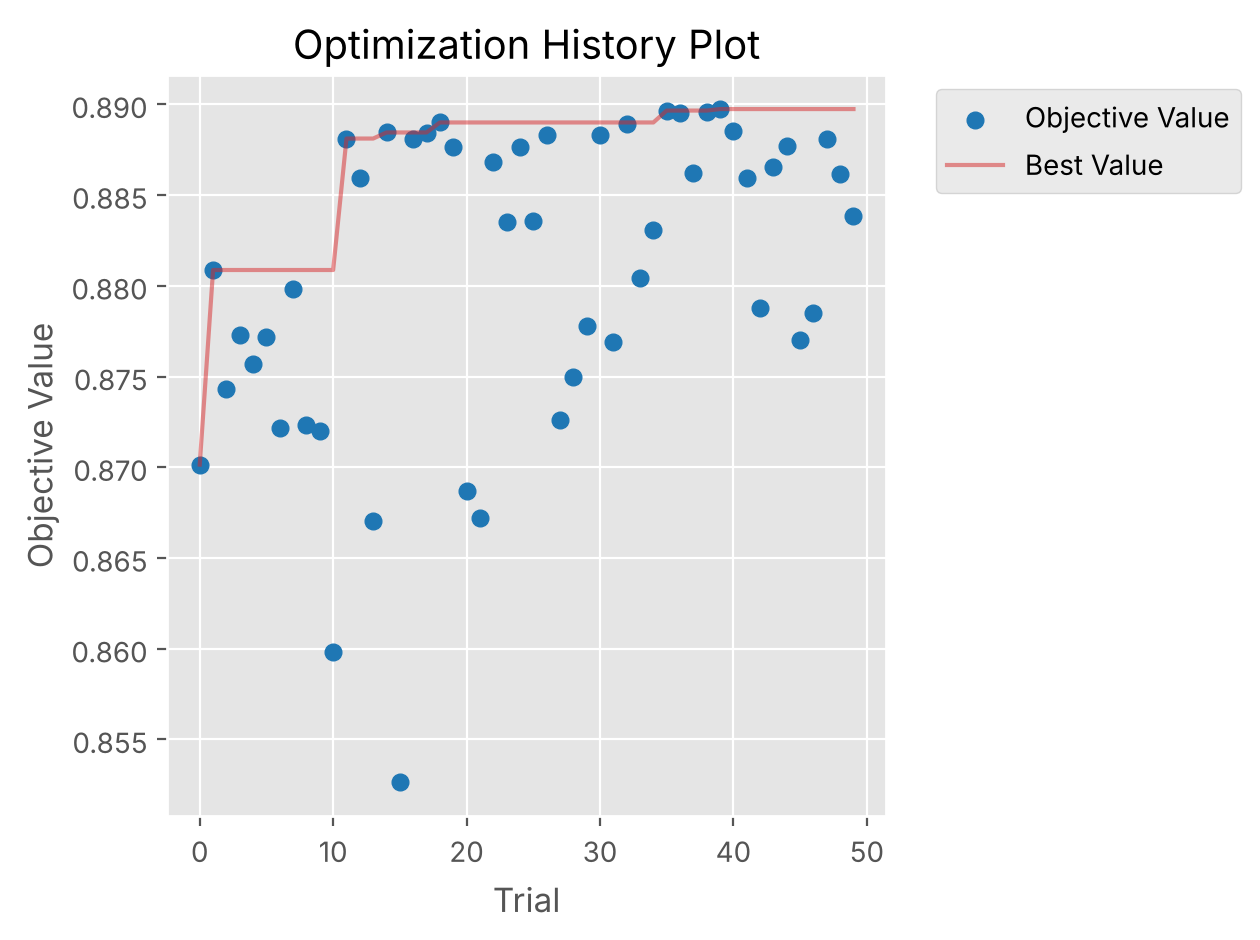

/tmp/ipykernel_1251/4052195749.py:4: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot(study).figure.savefig(f"../reports/lab3_optuna_{name}.png", bbox_inches="tight")


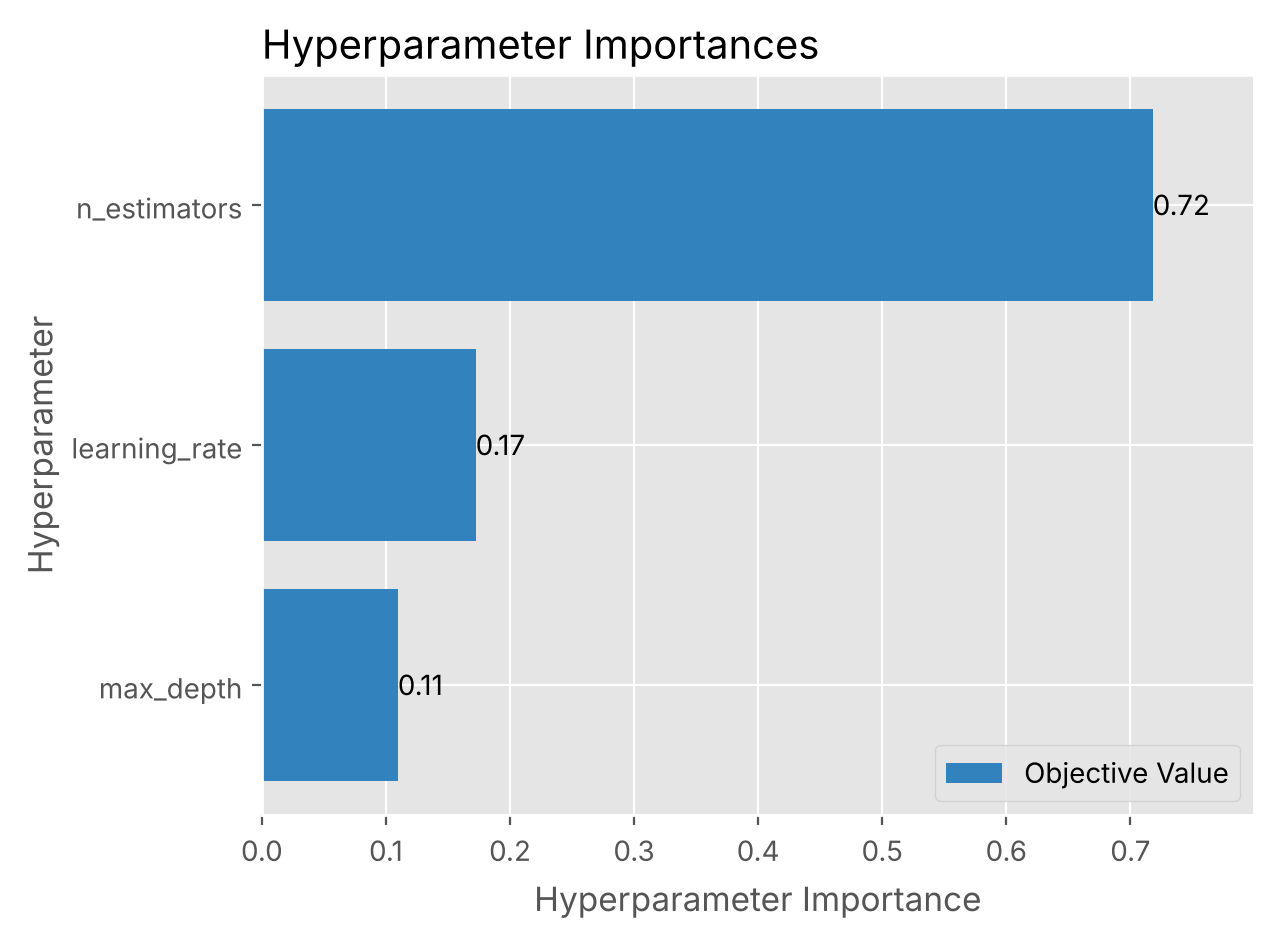

In [4]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

for plot, name in [(plot_optimization_history, "history"), (plot_param_importances, "importances")]:
    plot(study).figure.savefig(f"../reports/lab3_optuna_{name}.png", bbox_inches="tight")
    plt.show()

Первый график — история оптимизации: точки соответствуют trials, линия — лучшему значению на данный момент. Второй — важность гиперпараметров (fANOVA): какая доля разброса метрики объясняется каждым параметром.
Результат: важнее всего `n_estimators` (≈0.7), затем `learning_rate` (≈0.17), меньше всего `max_depth` (≈0.11). Число деревьев и шаг действуют вместе: значение имеет «суммарный шаг» `learning_rate × n_estimators`.
Лучшая конфигурация: маленький шаг (≈0.009), 550 деревьев глубины 2. Это много очень простых деревьев, каждое из которых учитывает максимум парное взаимодействие признаков. На 712 строках такая сильная регуляризация дала +0.02 ROC-AUC к дефолту (0.869 → 0.890).

## 4. Интерпретация: SHAP
SHAP-значение признака для объекта показывает его вклад в предсказание относительно среднего (`base value`). Вклады строго складываются: `base + Σ shap = выход модели` (для LightGBM это log-odds).
`TreeExplainer` вычисляет их точно и быстро за счёт структуры деревьев. Объясняем модель на признаках после предобработки, то есть на том, что реально видит LightGBM.

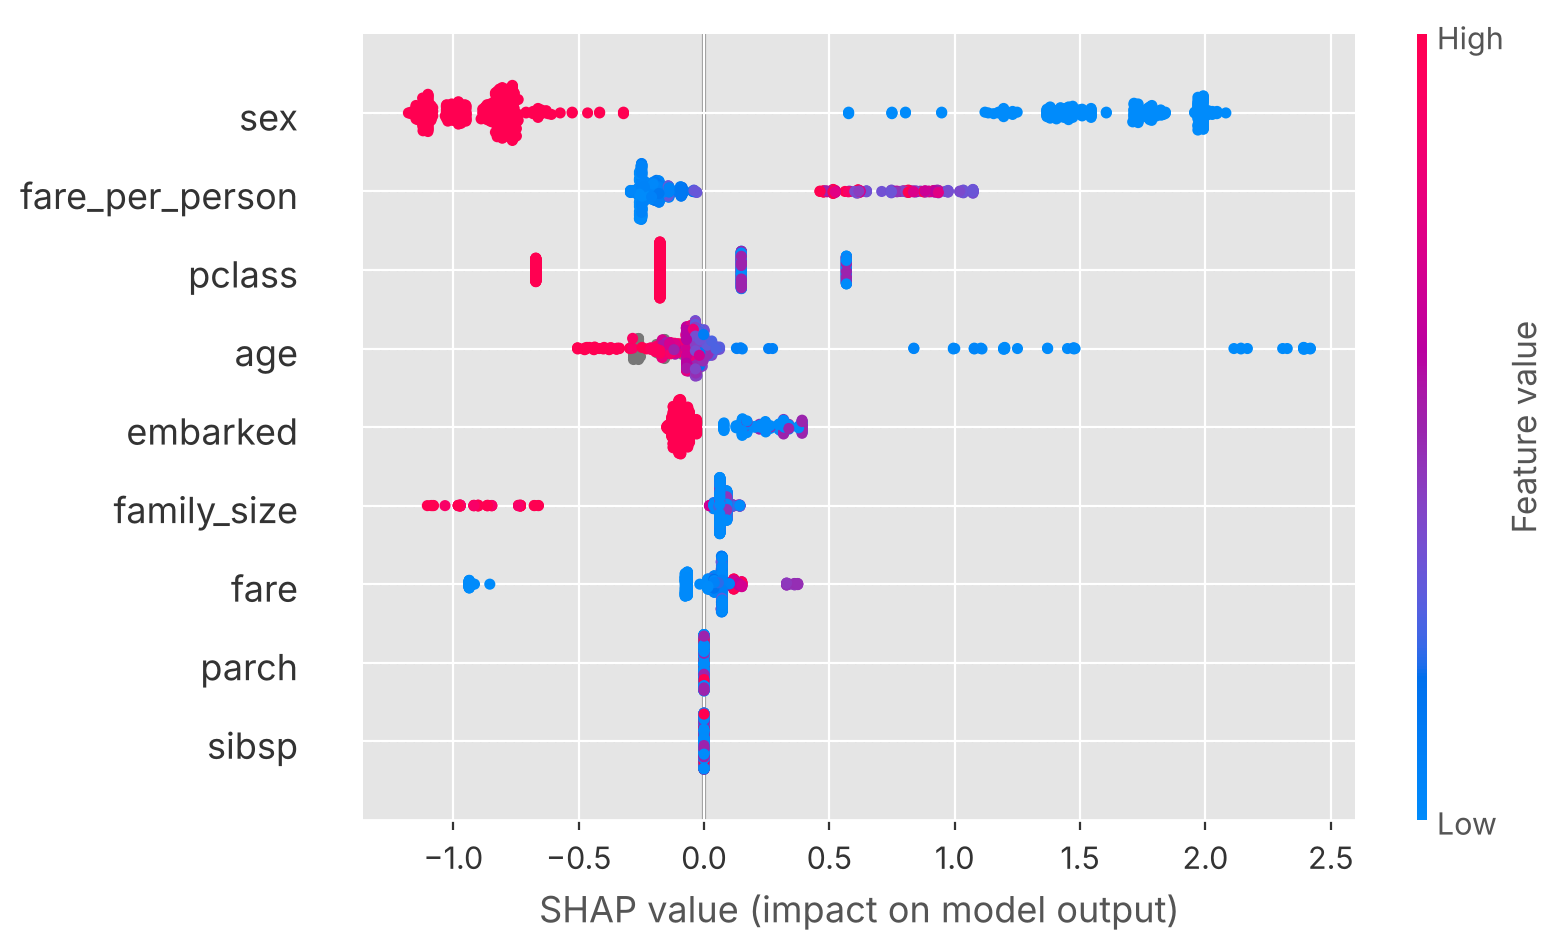

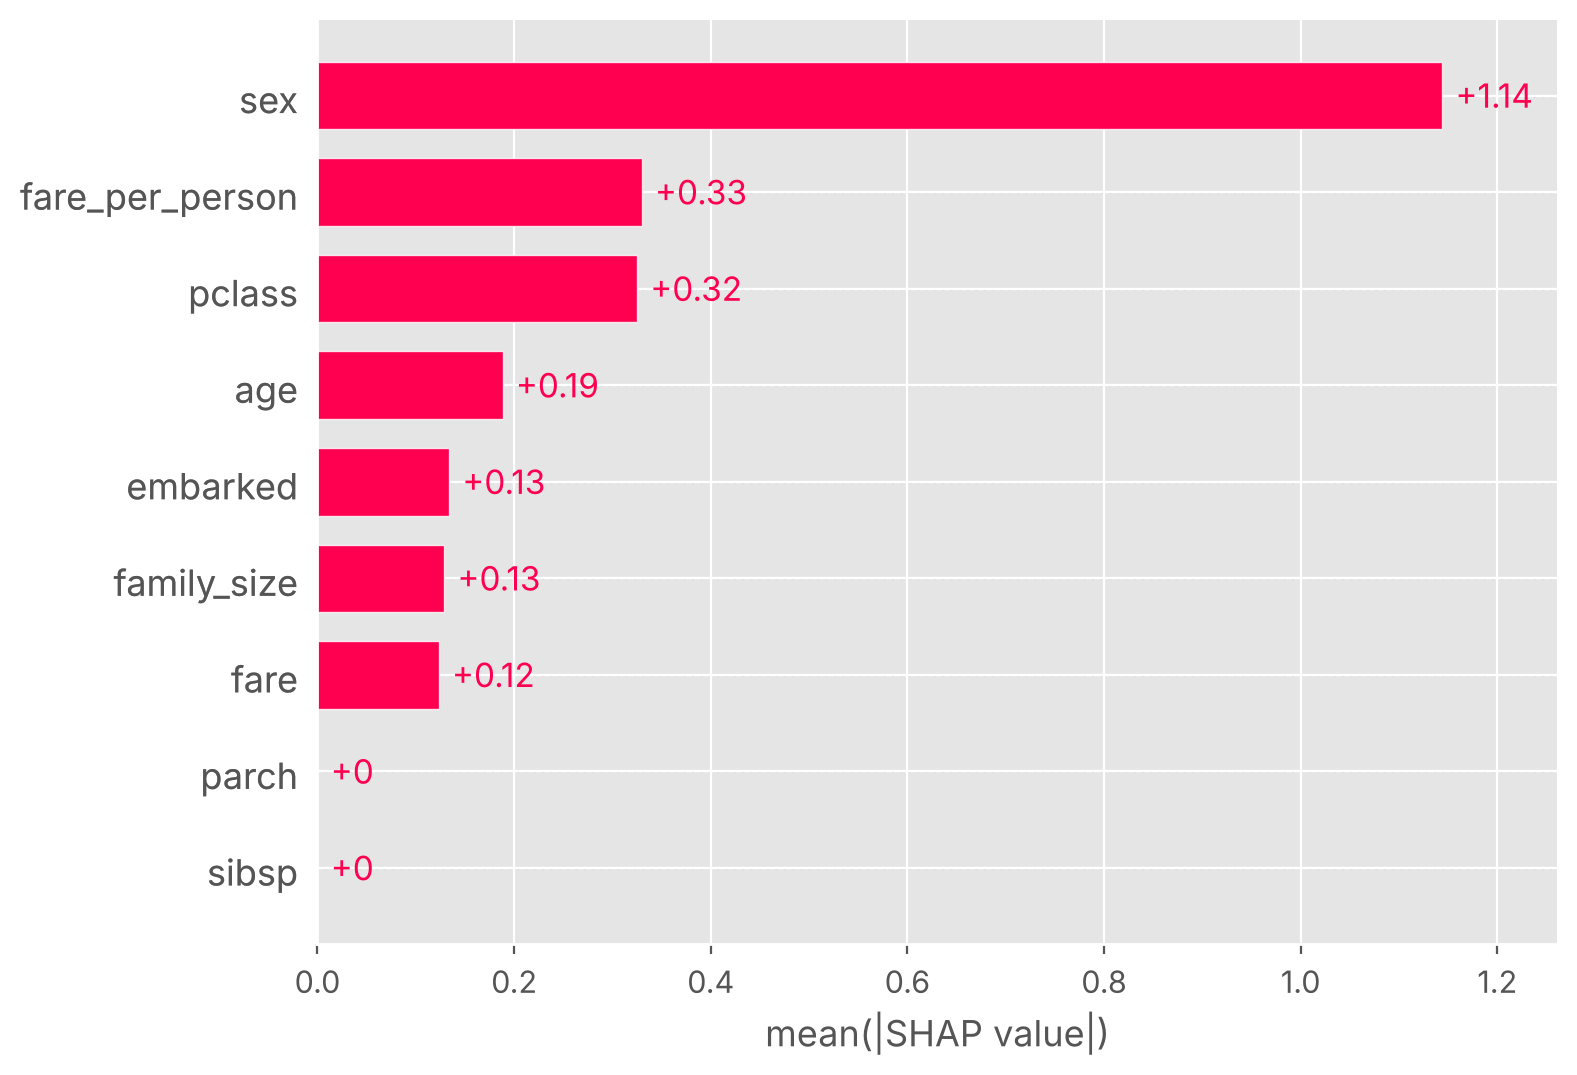

In [5]:
best_lgbm = tree_pipeline(lgbm(**best_params)).fit(X_train, y_train)
X_shap = best_lgbm[:-1].transform(X_train)          # все шаги, кроме модели
shap_values = shap.TreeExplainer(best_lgbm[-1])(X_shap)

shap.plots.beeswarm(shap_values, show=False)          # summary
plt.savefig("../reports/lab3_shap_summary.png", bbox_inches="tight")
plt.show()
shap.plots.bar(shap_values)

**Summary (beeswarm):** каждая точка — пассажир, цвет — значение признака, положение по оси X — вклад в log-odds выживания. **Bar:** средний |SHAP|, то есть глобальная важность.
Расшифровка кодов `OrdinalEncoder`: `sex` 0 = female, 1 = male; `embarked` 0 = C, 1 = Q, 2 = S; `pclass` 0/1/2 = 1/2/3 класс.

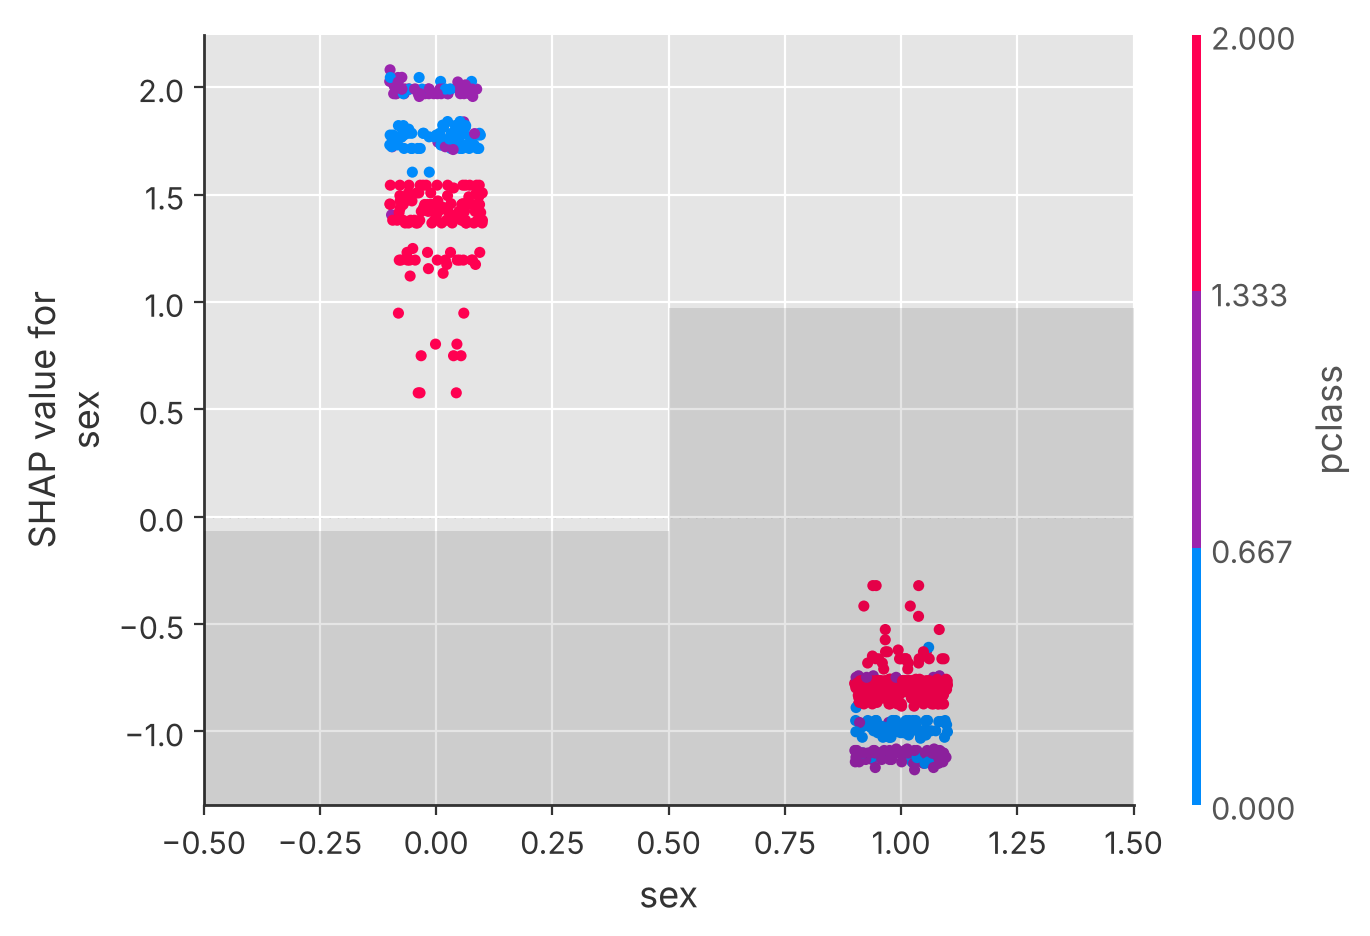

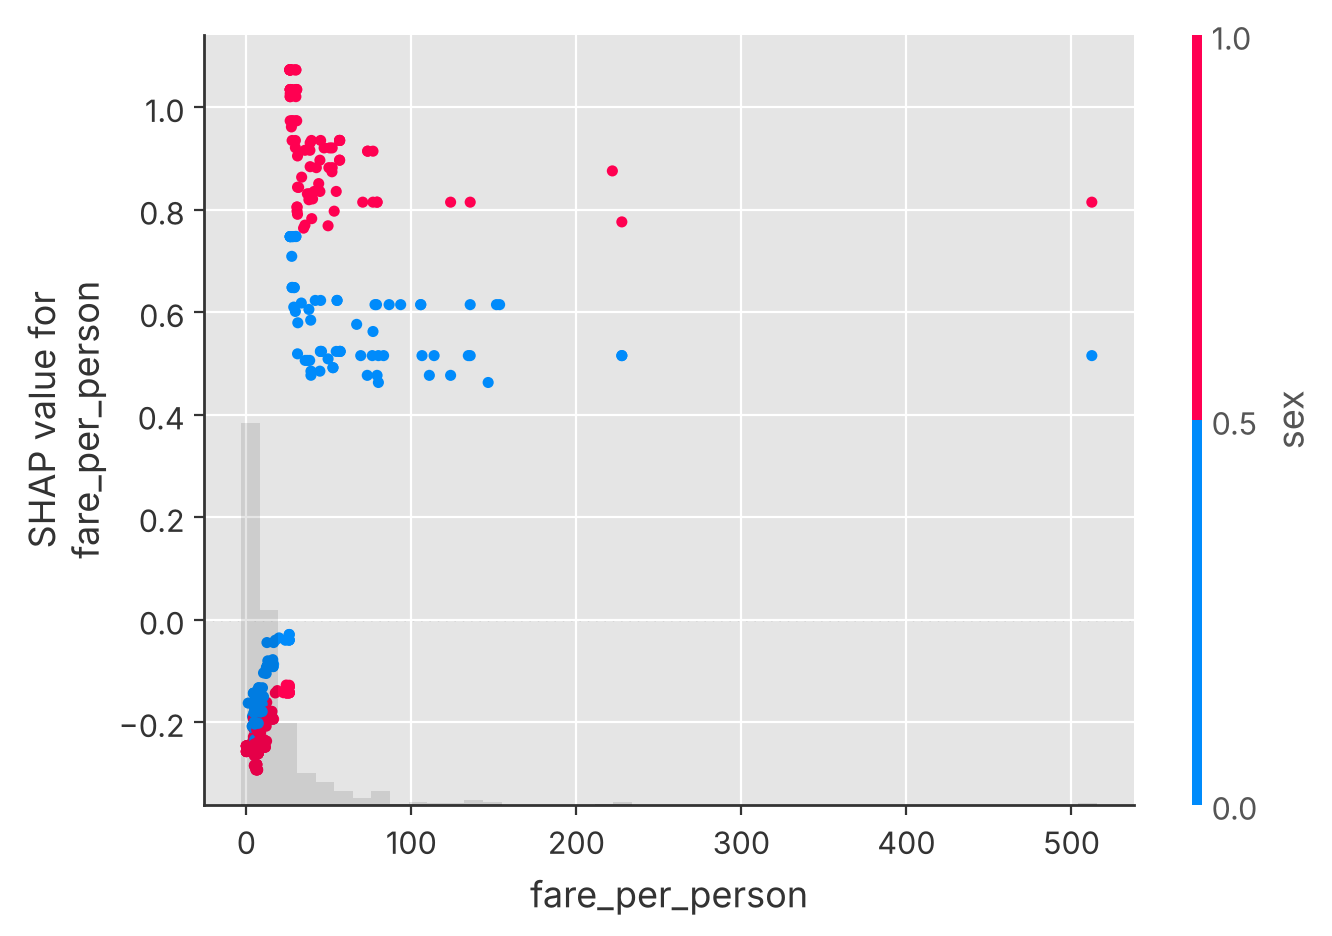

In [6]:
top2 = X_shap.columns[abs(shap_values.values).mean(0).argsort()[::-1][:2]]
for feat in top2:
    shap.plots.scatter(shap_values[:, feat], color=shap_values)  # цвет — признак с самым сильным взаимодействием

**Dependence:** по оси X отложено значение признака, по оси Y — его SHAP-вклад. Цветом SHAP автоматически выделяет признак, с которым у данного признака сильнее всего взаимодействие. Вертикальный разброс точек при одном и том же X показывает, что эффект зависит от других признаков.

P(survived) = 0.96


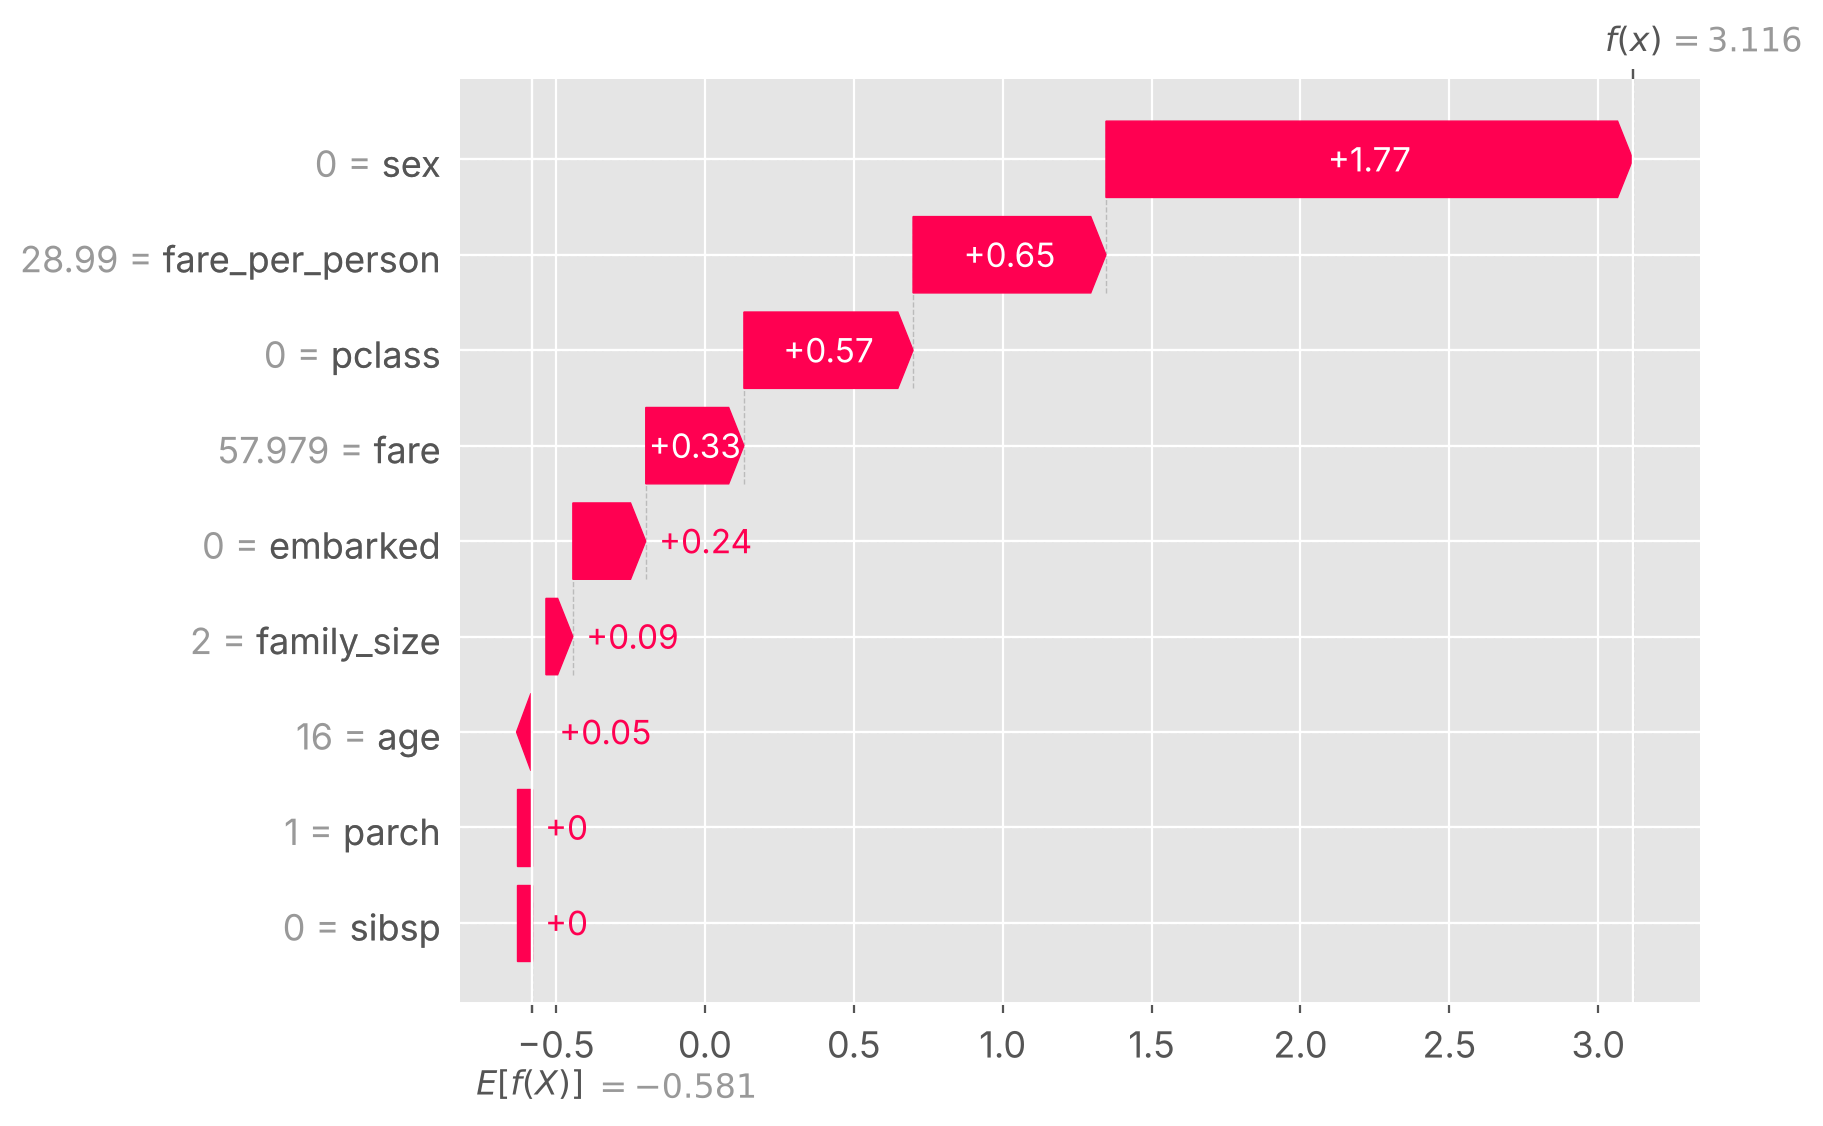

P(survived) = 0.04


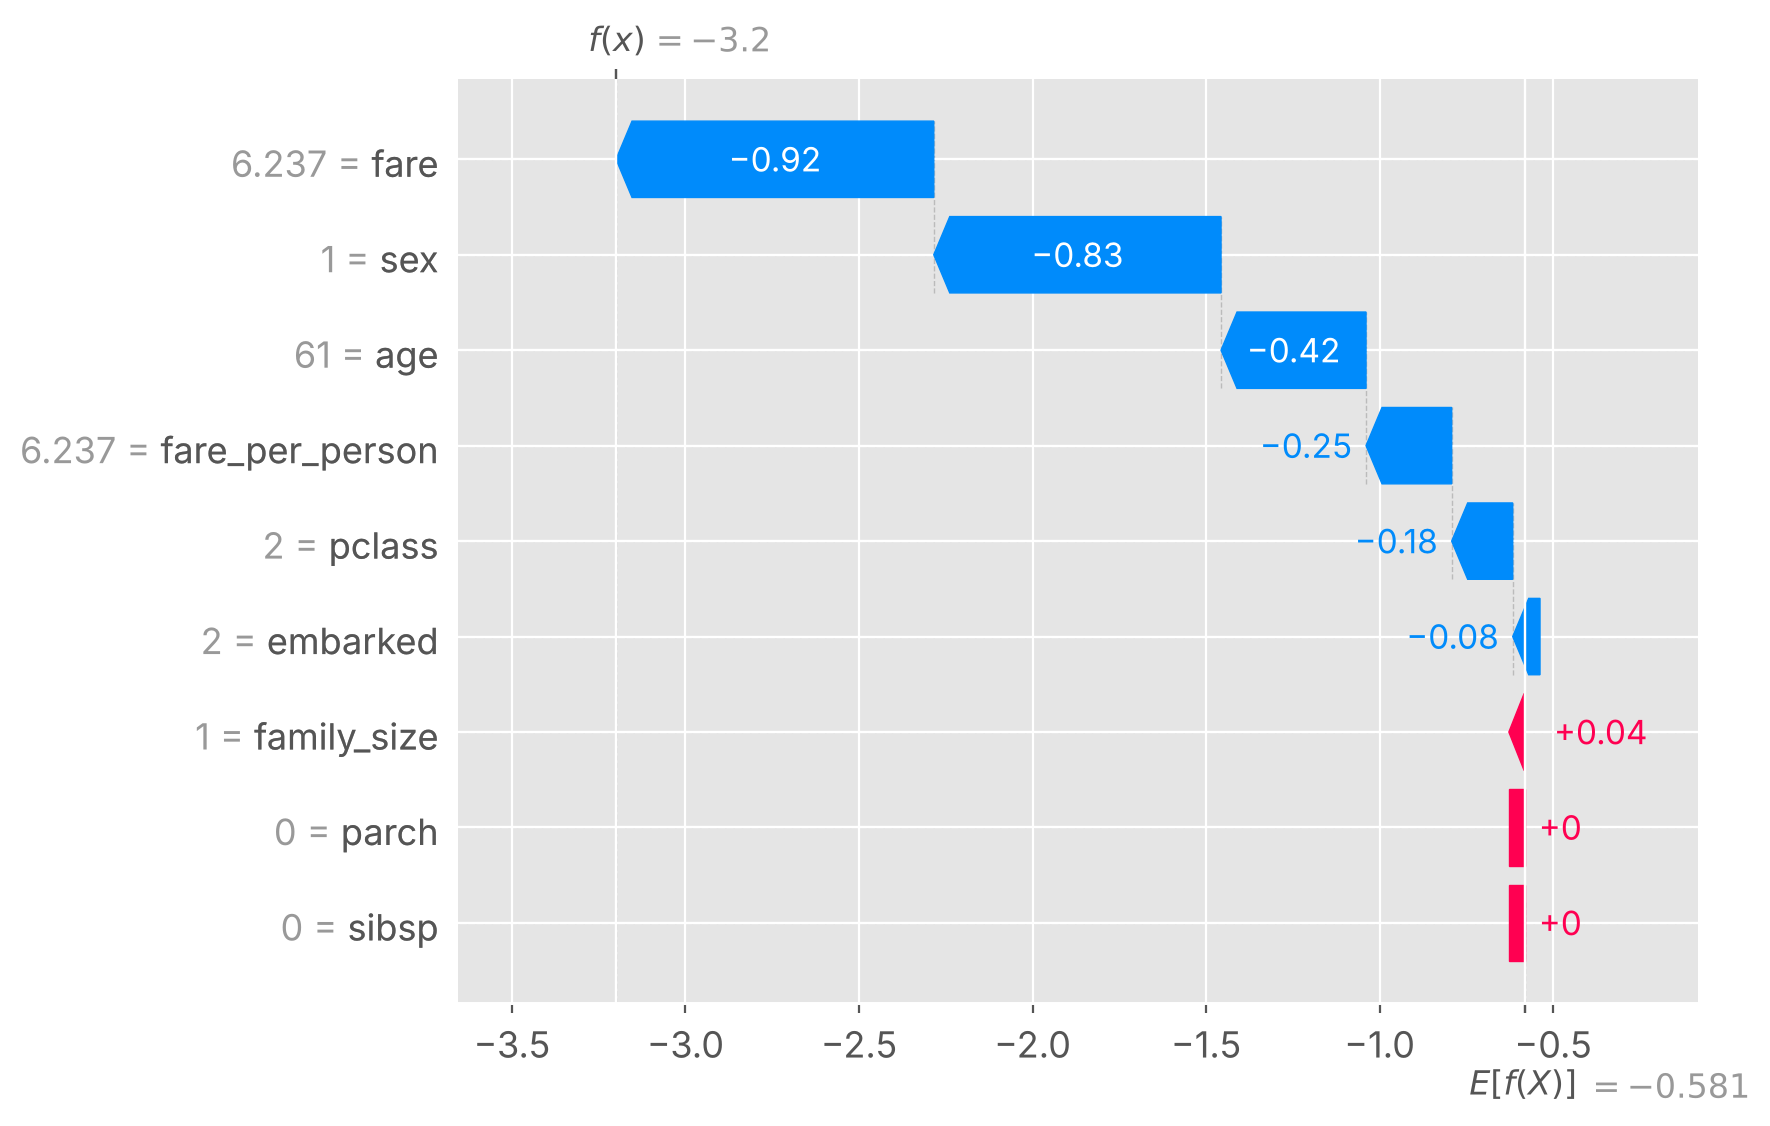

P(survived) = 0.50


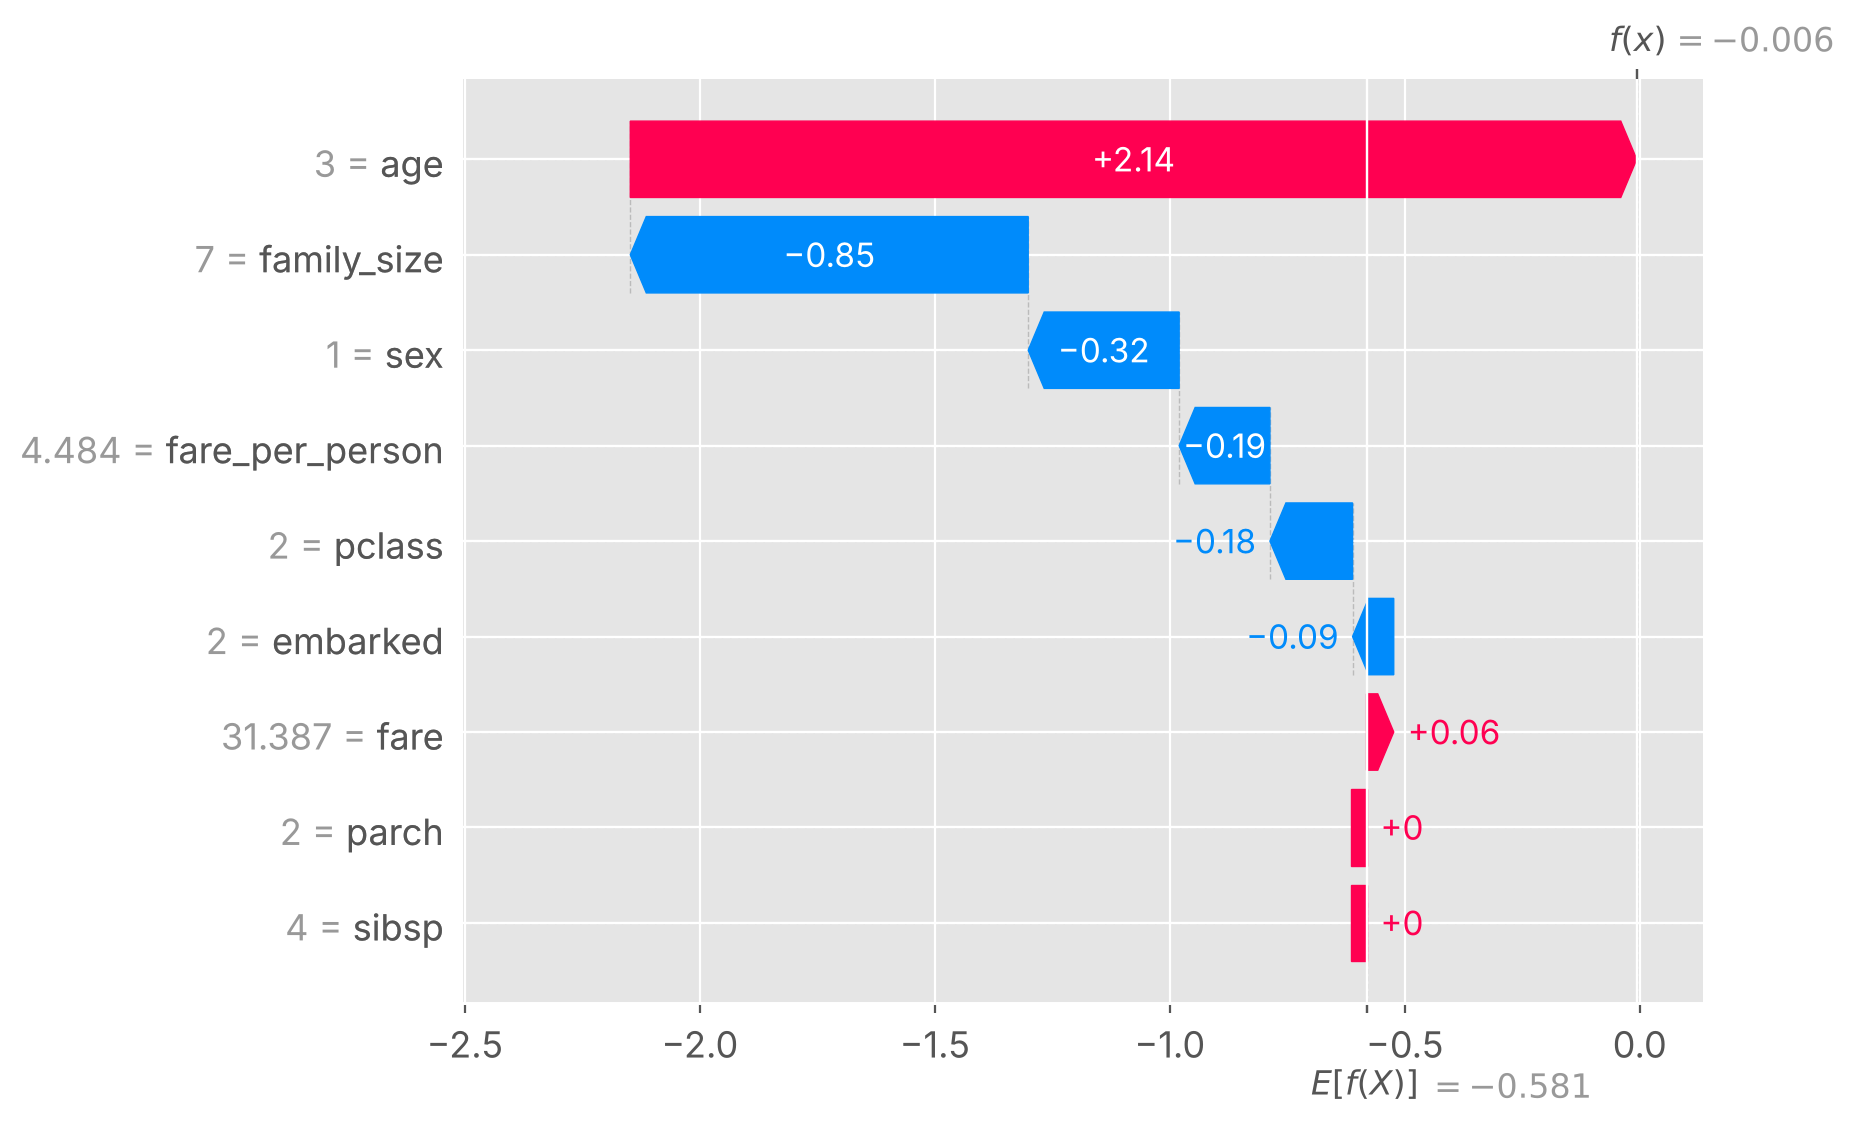

In [7]:
proba = best_lgbm.predict_proba(X_train)[:, 1]
for i in [proba.argmax(), proba.argmin(), abs(proba - 0.5).argmin()]:  # уверенно выжил / уверенно погиб / пограничный
    print(f"P(survived) = {proba[i]:.2f}")
    shap.plots.waterfall(shap_values[i])

**Waterfall** раскладывает одно предсказание: путь от `E[f(x)]` (средний log-odds) до `f(x)` конкретного пассажира с вкладом каждого признака. Взяты три объекта: самый уверенный «выжил», самый уверенный «погиб» и самый пограничный (P ≈ 0.5).

## 5. Стекинг: LightGBM + RandomForest + LogisticRegression
Базовые модели разнородные и ошибаются по-разному:
- **LightGBM** с параметрами из Optuna;
- **RandomForest**: бэггинг глубоких деревьев, дисперсия снижается усреднением (пропуски заполнены медианой/модой);
- **LogisticRegression**: финальный пайплайн из лабы 2 (Iterative-импутация, генерация признаков, L1-отбор, `C=0.1`), то есть линейная модель на one-hot и масштабированных признаках.

`StackingClassifier(cv=5, stack_method="predict_proba")`: каждая базовая модель делает out-of-fold предсказания вероятностей. Метамодель (логистическая регрессия) обучается на них и учится, кому из базовых моделей доверять. Out-of-fold нужен, чтобы метамодель не училась на предсказаниях моделей, которые уже видели эти объекты, иначе будет утечка.

In [8]:
logreg = build_pipeline(
    IterativeImputer(random_state=RANDOM_STATE), gen_features=True,
    select=SelectFromModel(LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1)),
).set_params(model__C=0.1)
rf = tree_pipeline(RandomForestClassifier(n_estimators=500, min_samples_leaf=3,
                                          random_state=RANDOM_STATE, n_jobs=-1), impute=True)
stack = StackingClassifier(
    estimators=[("lgbm", tree_pipeline(lgbm(**best_params))), ("rf", rf), ("logreg", logreg)],
    final_estimator=LogisticRegression(), cv=CV, stack_method="predict_proba", n_jobs=-1,
)
stacking = cv_report({"RandomForest": rf, "LogReg (лаба 2)": logreg,
                      "LightGBM (Optuna)": tree_pipeline(lgbm(**best_params)), "Stacking": stack},
                     X_train, y_train)
stacking.round(4)

,roc_auc,pr_auc,f1,roc_auc_std,fit_time_s
RandomForest,0.8852,0.8602,0.7650,0.0154,0.8420
LogReg (лаба 2),0.8590,0.8292,0.7494,0.0288,0.0292
LightGBM (Optuna),0.8897,0.8601,0.7392,0.0227,0.0452
Stacking,0.8908,0.8652,0.7497,0.0202,5.0466


In [9]:
# веса метамодели. Для бинарной задачи стекинг подаёт ей только P(класс 1) от каждой модели
meta = stack.fit(X_train, y_train).final_estimator_
pd.Series(meta.coef_[0], index=[n for n, _ in stack.estimators]).round(3)

lgbm      2.335
rf        2.614
logreg    1.005
dtype: float64

## 6. Дисбаланс: взвешивание классов
Выживших 38%, дисбаланс лёгкий. `class_weight="balanced"` умножает вес ошибки на объектах класса *k* на `n / (2 · n_k)`. Редкий класс (выжившие) получает вес ≈ 1.3, частый ≈ 0.8.
Ресемплинг не применяем, поэтому дополнительных шагов в пайплайне не нужно: меняется только функция потерь. Пайплайн остаётся `imblearn.Pipeline`, так что SMOTE при необходимости встраивается одним шагом.
Метрики по заданию: **PR-AUC** и **F1** (F1 считается при пороге 0.5).

In [10]:
imbalance = cv_report({
    "LightGBM (Optuna)": tree_pipeline(lgbm(**best_params)),
    "LightGBM (Optuna) + class_weight": tree_pipeline(lgbm(**best_params, class_weight="balanced")),
}, X_train, y_train)
imbalance.round(4)

,roc_auc,pr_auc,f1,roc_auc_std,fit_time_s
LightGBM (Optuna),0.8897,0.8601,0.7392,0.0227,0.2395
LightGBM (Optuna) + class_weight,0.8886,0.8607,0.7690,0.0232,0.2353


Взвешивание почти не меняет ROC-AUC и PR-AUC: это ранговые метрики, а веса в основном сдвигают вероятности вверх для класса 1, порядок объектов меняется слабо.
Меняется F1 при пороге 0.5: модель чаще говорит «выжил», recall растёт, precision падает. Такого же эффекта можно добиться, сдвинув порог без переобучения. Поэтому при лёгком дисбалансе взвешивание — скорее способ настроить баланс precision/recall, чем способ улучшить модель.

## 7. Финальная оценка на test
Кандидаты: оптимизированный LightGBM (с весами классов и без) и стекинг. Финальную модель выбираем по CV ROC-AUC **до** взгляда на test. Затем один раз оцениваем её на отложенных 20%.

In [11]:
summary = pd.concat([baseline, stacking, imbalance.iloc[[1]]])  # LightGBM (Optuna) уже есть в stacking
summary.round(4)

,roc_auc,pr_auc,f1,roc_auc_std,fit_time_s
XGBoost,0.8661,0.8430,0.7495,0.0205,0.0417
LightGBM,0.8688,0.8435,0.7519,0.0267,0.0454
CatBoost,0.8789,0.8504,0.7554,0.0235,0.5817
RandomForest,0.8852,0.8602,0.7650,0.0154,0.8420
LogReg (лаба 2),0.8590,0.8292,0.7494,0.0288,0.0292
LightGBM (Optuna),0.8897,0.8601,0.7392,0.0227,0.0452
Stacking,0.8908,0.8652,0.7497,0.0202,5.0466
LightGBM (Optuna) + class_weight,0.8886,0.8607,0.7690,0.0232,0.2353


In [12]:
candidates = {
    "LightGBM (Optuna)": tree_pipeline(lgbm(**best_params)),
    "LightGBM (Optuna) + class_weight": tree_pipeline(lgbm(**best_params, class_weight="balanced")),
    "Stacking": stack,
}
best_name = summary.loc[list(candidates), "roc_auc"].idxmax()
final = candidates[best_name].fit(X_train, y_train)
print("финальная модель:", best_name)
pd.Series(evaluate(final, X_test, y_test)).round(4)

финальная модель: Stacking


accuracy    0.7989
roc_auc     0.8422
pr_auc      0.8194
f1          0.7143
dtype: float64

In [13]:
save_model(final, "lab3_final.joblib")

saved /root/w/models/lab3_final.joblib


**Справочно, уже после выбора:** test-метрики остальных кандидатов и базовых моделей стекинга. На выбор эта таблица не влияет, иначе test превратился бы во вторую валидацию.
Test маленький (179 объектов): 95% бутстреп-интервал ROC-AUC имеет ширину около ±0.07. Поэтому различия в пределах 0.02–0.03 здесь — шум, а надёжный ориентир — CV на 712 объектах с 5 фолдами.

In [14]:
others = {**candidates, "RandomForest": rf, "LogReg (лаба 2)": logreg}
pd.DataFrame({n: evaluate(m.fit(X_train, y_train), X_test, y_test)
              for n, m in others.items() if n != best_name}).T.round(4)

,accuracy,roc_auc,pr_auc,f1
LightGBM (Optuna),0.7877,0.8287,0.7875,0.6724
LightGBM (Optuna) + class_weight,0.7933,0.8257,0.7790,0.7376
RandomForest,0.7933,0.8311,0.8038,0.7040
LogReg (лаба 2),0.7989,0.8638,0.8036,0.7188


## Выводы
1. **Бустинги «из коробки»** дают CV ROC-AUC 0.866–0.879 против 0.859 у LogReg из лабы 2. CatBoost лучший, но разница с остальными меньше std, а обучается он в 15–20 раз дольше. Для подбора выбран LightGBM.
2. **Optuna** (50 trials, TPE) подняла LightGBM с 0.869 до **0.890**. Это самый большой прирост в работе. Найдена сильная регуляризация: глубина 2, шаг ≈0.009, 550 деревьев. Главный гиперпараметр — `n_estimators`.
3. **SHAP:** главный признак — `sex`, у женщин сдвиг ≈ +1.5…+2 log-odds. Второй — `fare_per_person` (признак из лабы 2): ступенька около 25–30, ниже которой вклад отрицательный, выше — +0.5…+1. Далее идут `pclass` и `age`: у детей до ~10 лет большой положительный вклад («сначала женщины и дети»). `family_size` ≥ 5 сильно снижает шансы. `sibsp` и `parch` по отдельности почти не используются, их информацию взял на себя `family_size`.
   Dependence `sex` × `pclass` показывает взаимодействие: женщины 3-го класса получают от пола заметно меньший плюс, чем женщины 1–2-го.
4. **Стекинг** (0.891) почти не отличается от лучшей одиночной модели (0.890). Метамодель опирается на LightGBM и RF (веса ≈2.3 и 2.6), LogReg получает вес ≈1.0. Базовые модели сильно скоррелированы (два ансамбля деревьев на одних и тех же признаках), поэтому выигрыш от объединения мал, а время обучения выросло в ~100 раз.
5. **Взвешивание классов** при лёгком дисбалансе (38/62) почти не меняет ROC-AUC/PR-AUC, но поднимает F1 с 0.739 до 0.769: модель чаще предсказывает «выжил», recall растёт.
6. **Test** выбранного стекинга: ROC-AUC 0.842, accuracy 0.80. Это ниже CV и даже ниже LogReg на том же test (0.864), однако на 179 объектах интервал неопределённости ±0.07, и все кандидаты в него попадают. На Titanic потолок сложных моделей низкий: сигнал в основном содержится в 3–4 признаках, которые хорошо улавливает и линейная модель.